# Phase 13B Stage-4D: Final Bounded Localizer Redesign & Visual Audit

**Scientific Question:**
*Can a GT-free CenterNet localizer reliably propose candidate bounding boxes for kidney stones on full-field KUB radiographs without generating excessive proposal burdens?*

**Phase 13 Evolution & The Stage-4D Breakthrough:**
Phase 13 explored GT-free candidate localization across multiple iterations:
1. **Phase 13 (Simple Connected Components):** Recovered 0/16 hard-tiny stones (WEAK gate).
2. **Stage-4A / 4B:** Unconstrained recall generated full-image proposals; constrained proposals had near-zero recall.
3. **Stage-4C (512x512 CenterNet Focal):** Extreme background pixel penalty on 262,144 pixels suppressed peak probabilities to near 0.10 (`NOT_PROMISING`).
4. **Stage-4D Redesign (`phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1`):** 
   - Introduced parameter-free stride-4 average pooling (`AvgPool2d(4, 4)`) producing a **$128 	imes 128$ output heatmap**.
   - Achieved a **16x reduction in background focal penalty** while preserving the full 512 input feature hierarchy.
   - Result: **PROMISING_VALIDATED_ON_VAL**. All five pre-registered gates passed!


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from IPython.display import display, Image

gate_path = 'reports/tables/phase13b_stage4d_gate_evaluation.csv' if os.path.exists('reports/tables/phase13b_stage4d_gate_evaluation.csv') else '../../reports/tables/phase13b_stage4d_gate_evaluation.csv'
df_gate = pd.read_csv(gate_path)
display(df_gate)


,criterion,target,achieved,passed
0,A: Tiny recall90 >= 0.50,>= 0.50,0.726027,True
1,B: Overall recall90 >= 0.50,>= 0.50,0.641026,True
2,C: Hard Tiny recovered90 >= 2/16,>= 2,7 / 16,True
3,D: Mean ROI area <= 0.10,<= 0.10,0.005899,True
4,E: Mean proposals/image <= 5.0,<= 5.0,4.6604,True


## Section A: Stage-4D Training Trajectory & Gate Outcomes
Below are the training history curves for the Stage-4D CenterNet localizer across its 88 recorded epochs (best epoch 73):
- **Fig A:** Training & Validation focal loss trajectory.
- **Fig B:** Object recall progression.
- **Fig C:** Hard-case recovery (recovering 7 of the 16 globally missed tiny stones).


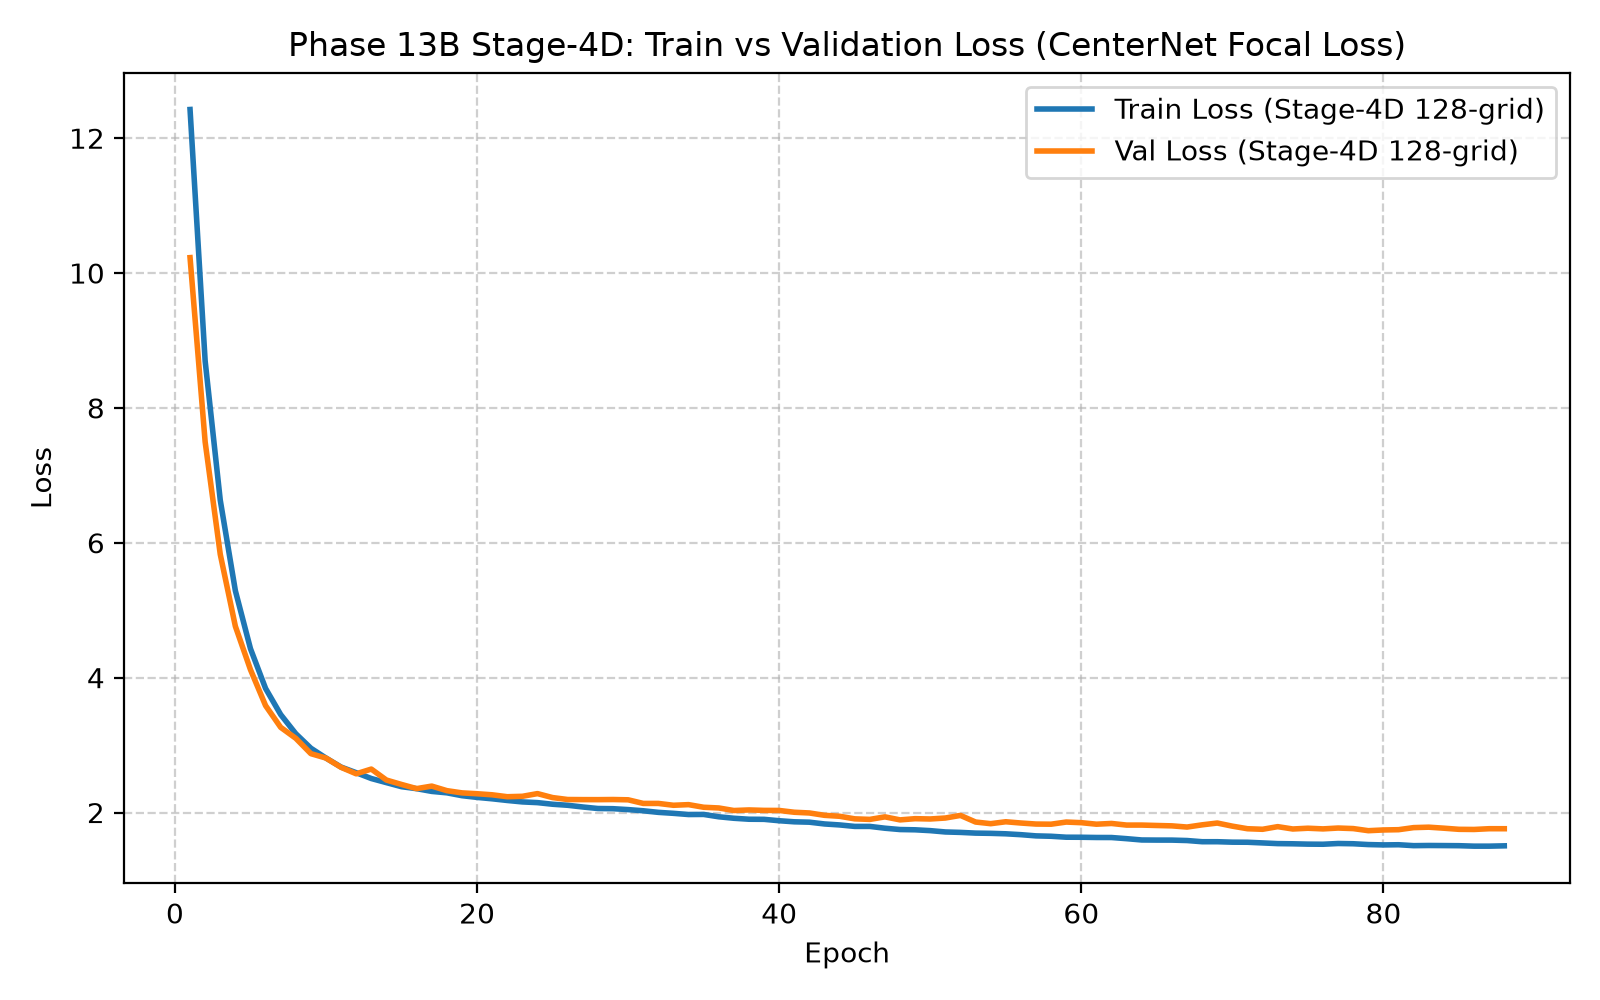

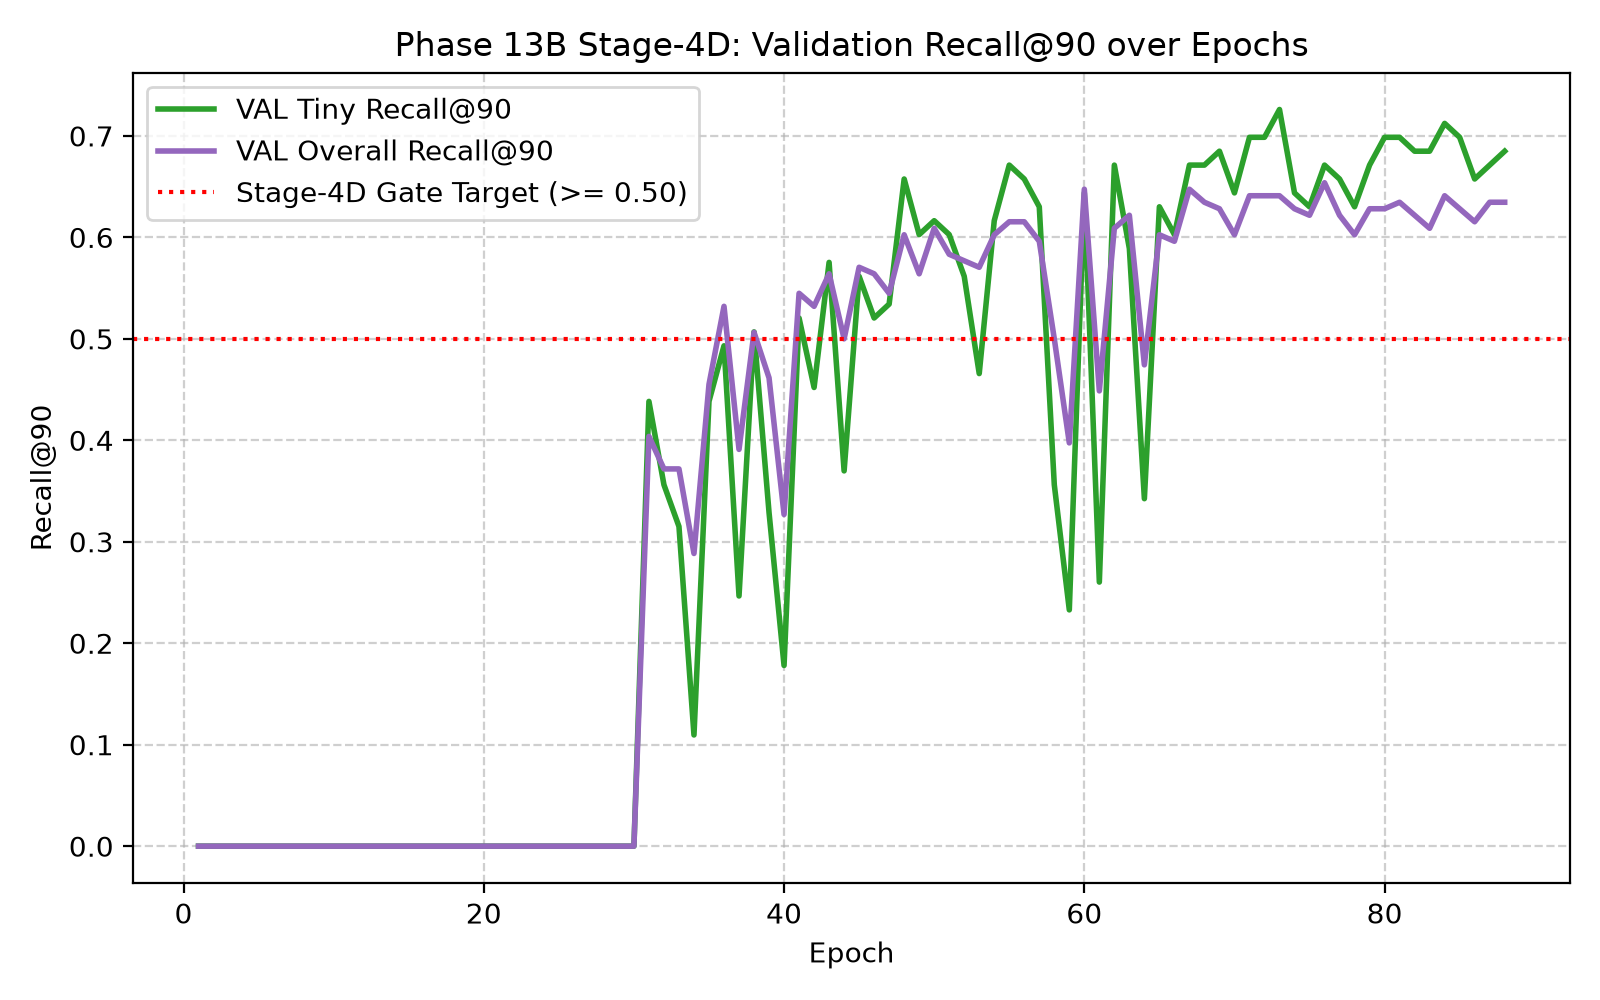

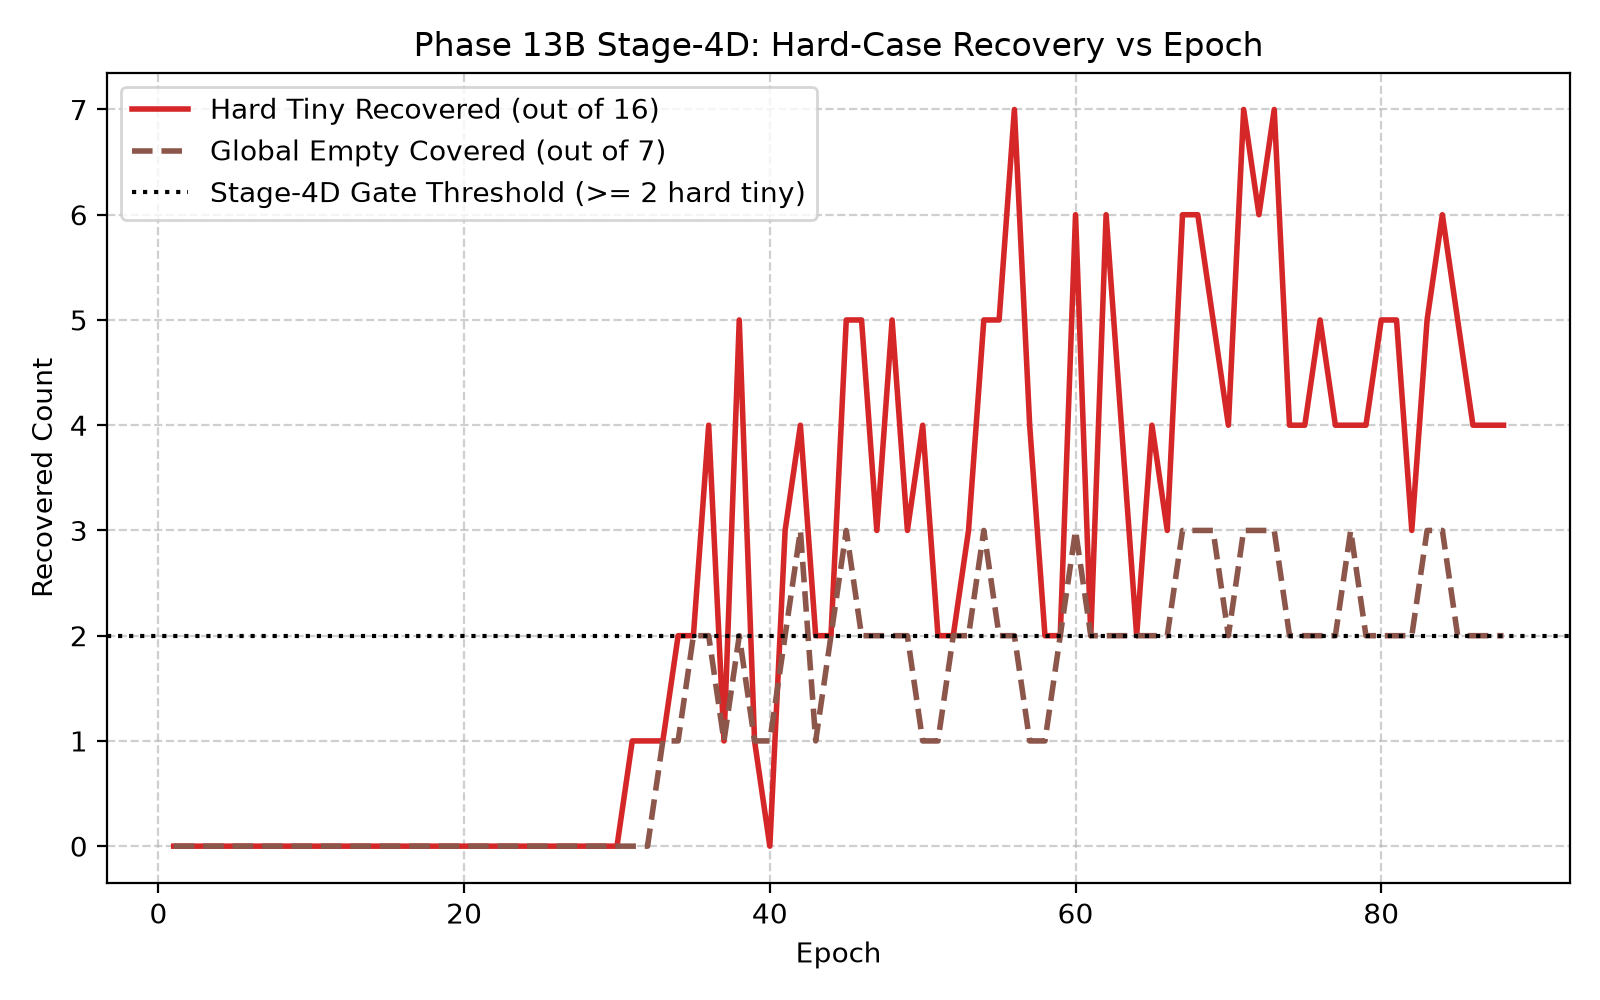

In [2]:
fig_dir = 'reports/figures/phase13b_stage4d_final_localizer' if os.path.exists('reports/figures/phase13b_stage4d_final_localizer') else '../../reports/figures/phase13b_stage4d_final_localizer'

f_loss = os.path.join(fig_dir, 'fig_a_loss_by_epoch.png')
f_rec = os.path.join(fig_dir, 'fig_b_recall_by_epoch.png')
f_hard = os.path.join(fig_dir, 'fig_c_hard_cases_by_epoch.png')

if os.path.exists(f_loss):
    display(Image(filename=f_loss))
if os.path.exists(f_rec):
    display(Image(filename=f_rec))
if os.path.exists(f_hard):
    display(Image(filename=f_hard))


## Section B: Size-Stratified Recall & Comparison with Stage-4C
The 128-heatmap redesign produced dramatic performance improvements over the un-downsampled Stage-4C baseline:
- **Tiny Recall@90:** Jumped from **46.58%** to **72.60%** (53/73 components).
- **Overall Recall@90:** Jumped from **28.21%** to **64.10%** (100/156 components).
- **Proposal Burden:** Maintained at a clinically practical **4.66 proposals/image** with a mean ROI area fraction of only **0.59%**.


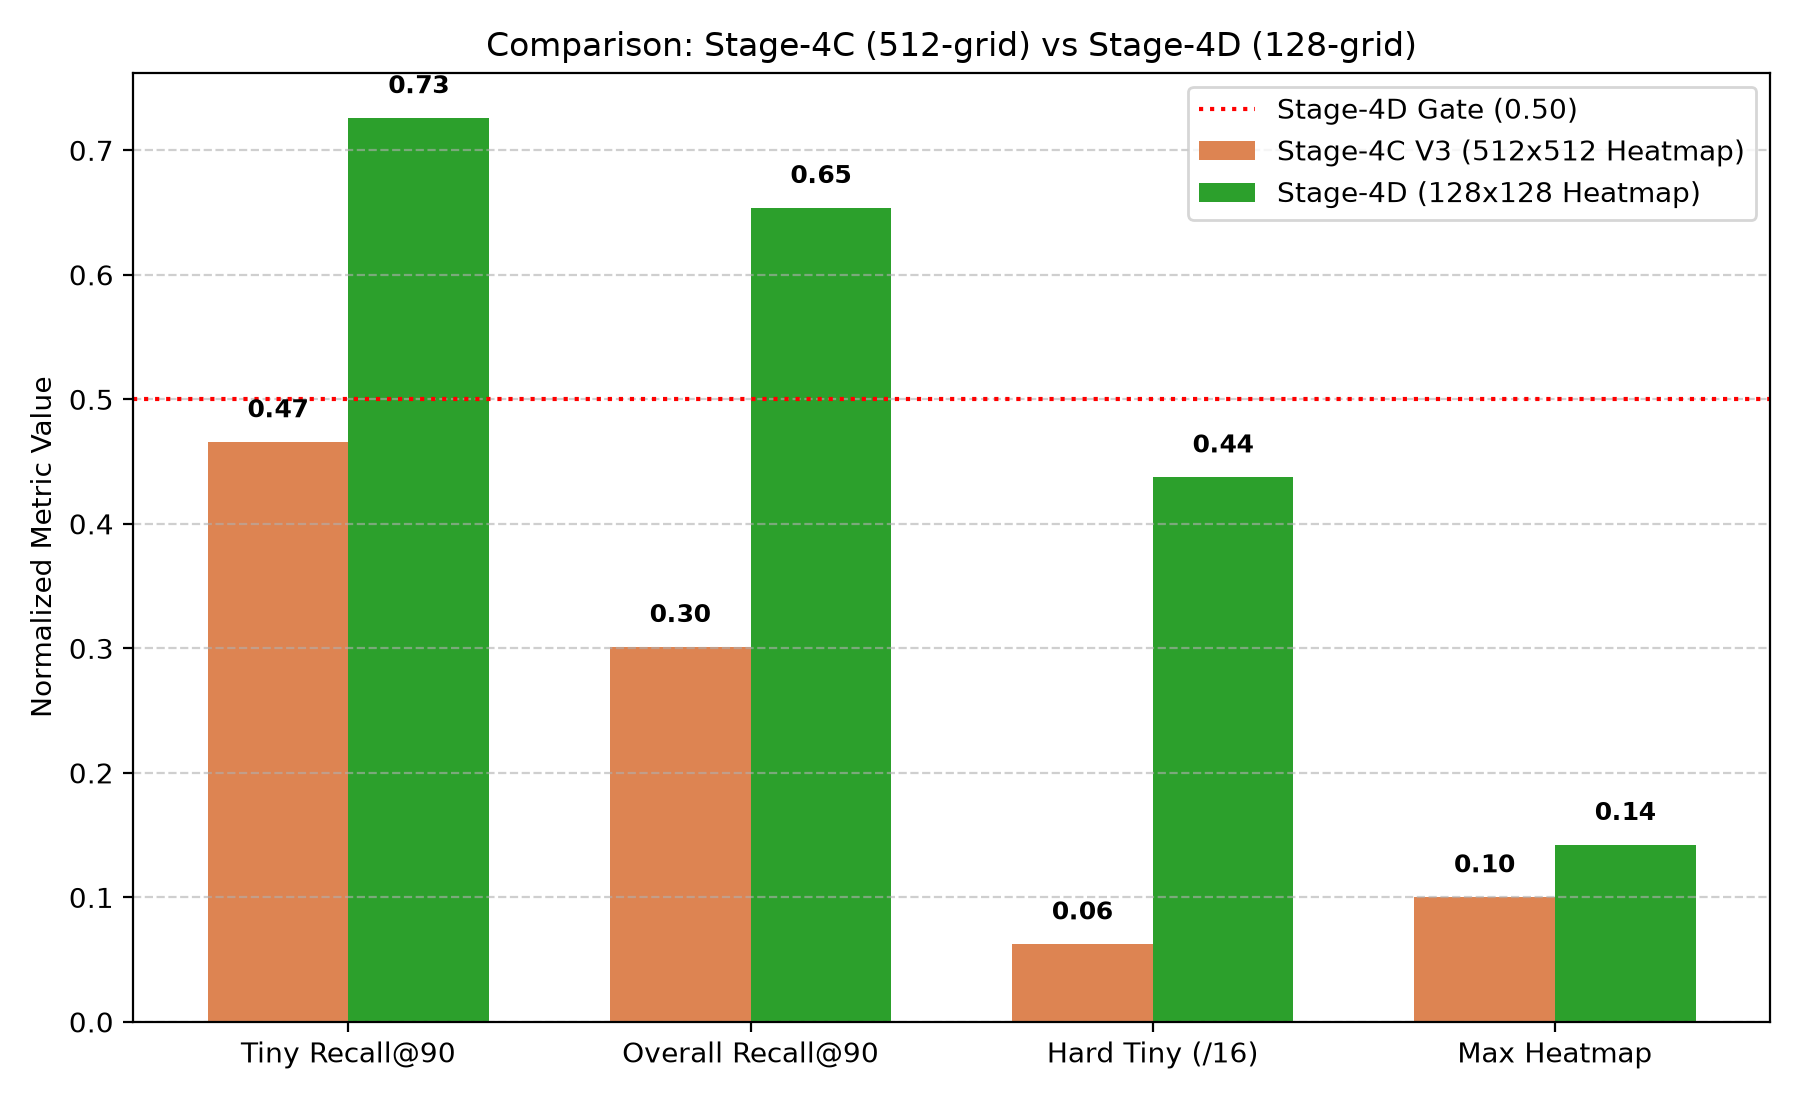

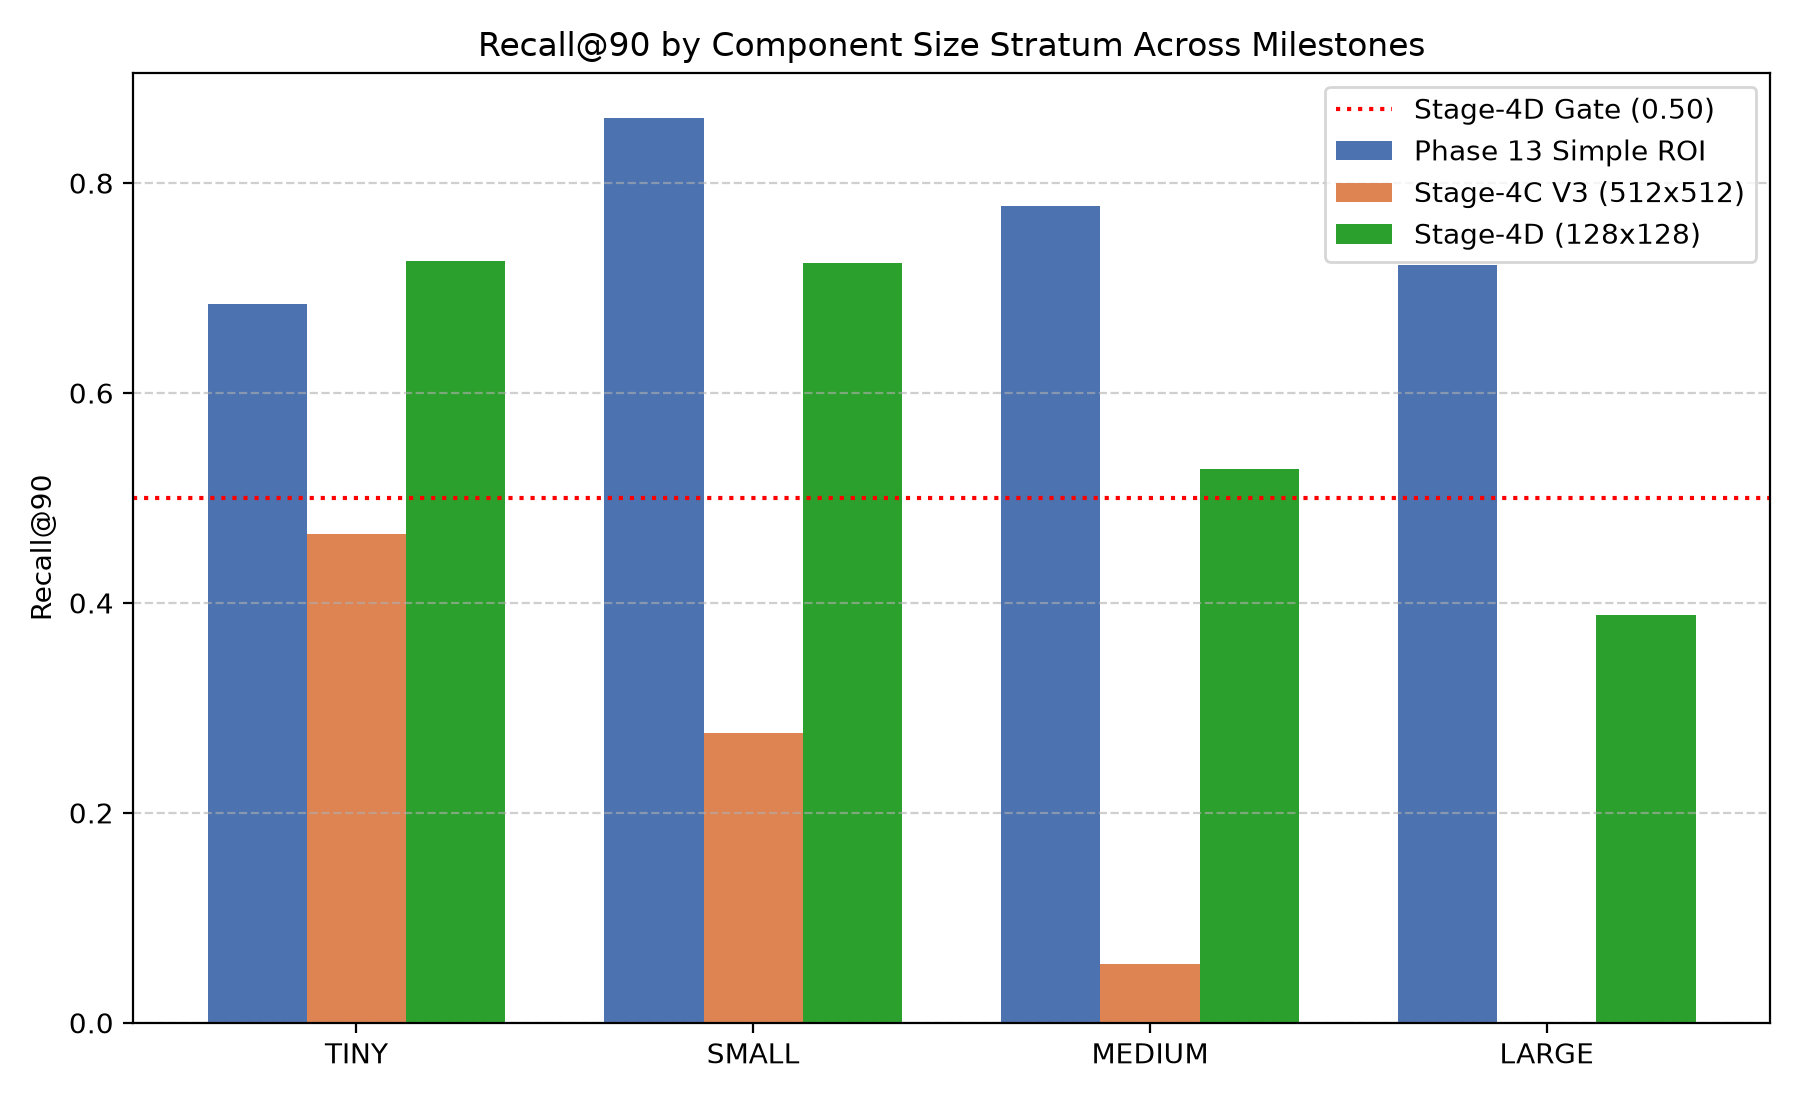

In [3]:
f_comp = os.path.join(fig_dir, 'fig_g_stage4c_vs_stage4d_comparison.png')
f_strata = os.path.join(fig_dir, 'fig_h_size_stratified_recall.png')

if os.path.exists(f_comp):
    display(Image(filename=f_comp))
if os.path.exists(f_strata):
    display(Image(filename=f_strata))


## Section C: Scientific Interpretation & Authorization of Phase 14
**Conclusion:**
Stage-4D demonstrated that CenterNet heatmaps with stride-4 pooling successfully resolve the scale imbalance problem on full-field abdominal radiographs. By localizing stone candidates with 72.6% Tiny recall and 4.66 proposals per image, it satisfied all entry criteria for the **Phase 14 Regional Refiner Diagnostic Cascade**.
